# Problem 1 — Pendulum with and without damping: figures

Code for the three figures in the Problem 1 solutions:

| Part | Figure | File |
|---|---|---|
| (a) | Phase portrait of the undamped pendulum | `Images/P1a_phase_portrait.pdf` |
| (b) | Phase portraits of the damped pendulum (three regimes) | `Images/P1b_phase_portraits_damped.pdf` |
| (c) | $\theta(t)$ and $E(t)$ along a damped trajectory | `Images/P1c_energy_decay.pdf` |

$$\ddot\theta + 2\gamma\dot\theta + \omega^2\sin\theta = 0, \qquad \dot\theta = v,\quad \dot v = -2\gamma v - \omega^2\sin\theta, \qquad E = \tfrac12 v^2 + \omega^2(1-\cos\theta).$$

Units: $\omega = 1$ throughout. Run the cells in order from this folder (`Code/Problem-1`). Figures are saved to `../../Images`.

## Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp

%matplotlib inline

plt.rcParams.update({
    "mathtext.fontset": "cm",
    "font.family": "serif",
    "font.size": 11,
})

# Output folder: <project>/Images (this notebook lives in <project>/Code/Problem-1)
IMG_DIR = Path("../../Images").resolve()
IMG_DIR.mkdir(exist_ok=True)


def save(fig, name):
    """Save a figure as vector PDF (for LaTeX) and PNG (for preview)."""
    fig.savefig(IMG_DIR / f"{name}.pdf")
    fig.savefig(IMG_DIR / f"{name}.png", dpi=200)
    print("saved", IMG_DIR / f"{name}.pdf")


# Colours (validated categorical palette, light mode)
BLUE, VIOLET, RED, ORANGE = "#2a78d6", "#6250d6", "#e34948", "#eb6834"
C_INK, C_MUTED, C_FIELD = "#0b0b0b", "#8a8985", "#c9c8c3"

omega = 1.0

## (a) Conservative motion — phase portrait

Orbits are level sets of $E$. The upright saddle has $E = 2\omega^2$, and the separatrix is
$$v_\pm(\theta) = \pm 2\omega\cos(\theta/2), \qquad -\pi \le \theta \le \pi .$$
Orbits with $E<2\omega^2$ are closed oscillations (shaded region). Orbits with $E>2\omega^2$ are rotations.
Arrows point along the vector field $(\dot\theta, \dot v) = (v, -\omega^2\sin\theta)$.

saved /home/stavros/Desktop/UOC MASTERS COURSES/Mathematical methods/5 Problem sets/MMP Set 2 Vogiatzis/Images/P1a_phase_portrait.pdf


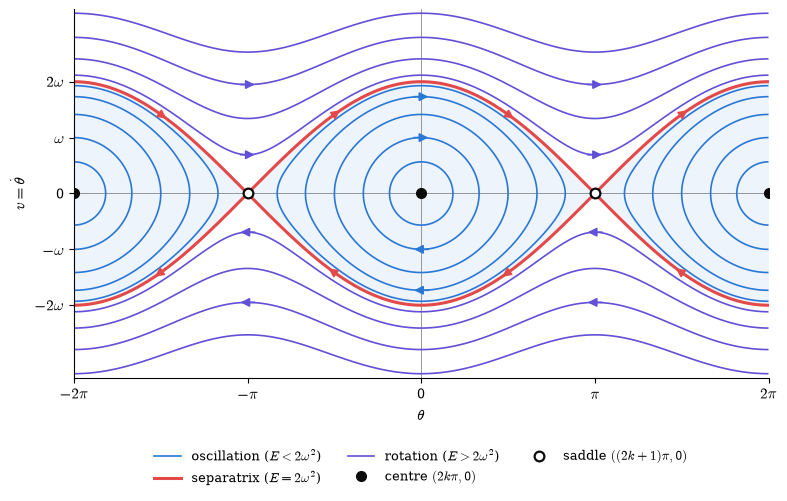

In [2]:
E_sep = 2 * omega**2                         # energy of the upright saddle

th = np.linspace(-2 * np.pi, 2 * np.pi, 1201)
vmax = 3.3
v = np.linspace(-vmax, vmax, 801)
TH, V = np.meshgrid(th, v)
E = 0.5 * V**2 + omega**2 * (1 - np.cos(TH))

fig, ax = plt.subplots(figsize=(8, 5.2))

# shade the oscillation region (inside the separatrix)
v_sep = 2 * omega * np.abs(np.cos(th / 2))
ax.fill_between(th, -v_sep, v_sep, color=BLUE, alpha=0.08, lw=0)

# ordinary orbits
E_osc = E_sep * np.array([0.08, 0.25, 0.5, 0.75, 0.93])
E_rot = E_sep * np.array([1.12, 1.45, 1.95, 2.6])
ax.contour(TH, V, E, levels=E_osc, colors=BLUE, linewidths=1.2)
ax.contour(TH, V, E, levels=E_rot, colors=VIOLET, linewidths=1.2)

# separatrix  v = ±2 omega cos(theta/2)
for s in (+1, -1):
    ax.plot(th, s * v_sep, color=RED, lw=2.2)


def arrow(t0, v0, color):
    """Arrowhead at (t0, v0) along the field (theta', v') = (v, -omega^2 sin theta)."""
    d = np.array([v0, -omega**2 * np.sin(t0)])
    d = 0.18 * d / np.linalg.norm(d)
    ax.annotate("", xy=(t0 + d[0], v0 + d[1]), xytext=(t0 - d[0], v0 - d[1]),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2,
                                mutation_scale=13), zorder=5)


for En in E_osc[1::2]:                           # oscillations (central well)
    vt = np.sqrt(2 * En)
    arrow(0.0, vt, BLUE)
    arrow(0.0, -vt, BLUE)
for En in E_rot[::2]:                            # rotations
    for t0 in (-np.pi, np.pi):
        vt = np.sqrt(2 * (En - 2 * omega**2))
        arrow(t0, vt, VIOLET)
        arrow(t0, -vt, VIOLET)
for t0 in (-np.pi / 2, np.pi / 2, -3 * np.pi / 2, 3 * np.pi / 2):  # separatrix
    vs = 2 * omega * abs(np.cos(t0 / 2))
    arrow(t0, vs, RED)
    arrow(t0, -vs, RED)

# equilibria
ax.plot([-2 * np.pi, 0, 2 * np.pi], [0] * 3, "o", ms=7, color=C_INK, zorder=6)
ax.plot([-np.pi, np.pi], [0] * 2, "o", ms=7, mfc="white", mec=C_INK, mew=1.6, zorder=6)

# legend
handles = [
    Line2D([], [], color=BLUE, lw=1.2, label=r"oscillation ($E<2\omega^2$)"),
    Line2D([], [], color=RED, lw=2.2, label=r"separatrix ($E=2\omega^2$)"),
    Line2D([], [], color=VIOLET, lw=1.2, label=r"rotation ($E>2\omega^2$)"),
    Line2D([], [], ls="", marker="o", ms=7, color=C_INK, label=r"centre $(2k\pi,0)$"),
    Line2D([], [], ls="", marker="o", ms=7, mfc="white", mec=C_INK, mew=1.6,
           label=r"saddle $((2k+1)\pi,0)$"),
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.16),
          ncol=3, frameon=False, fontsize=9.5)

# axes
ax.axhline(0, color=C_MUTED, lw=0.6, zorder=0)
ax.axvline(0, color=C_MUTED, lw=0.6, zorder=0)
ax.set_xlim(-2 * np.pi, 2 * np.pi)
ax.set_ylim(-vmax, vmax)
ax.set_xticks(np.arange(-2, 3) * np.pi)
ax.set_xticklabels([r"$-2\pi$", r"$-\pi$", r"$0$", r"$\pi$", r"$2\pi$"])
ax.set_yticks([-2, -1, 0, 1, 2])
ax.set_yticklabels([r"$-2\omega$", r"$-\omega$", r"$0$", r"$\omega$", r"$2\omega$"])
ax.set_xlabel(r"$\theta$")
ax.set_ylabel(r"$v=\dot\theta$")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

fig.tight_layout()
save(fig, "P1a_phase_portrait")
plt.show()

## (b) Linear damping — phase portraits in three regimes

The trajectories are integrated numerically with `solve_ivp`.
- **Saddles** $(\pm\pi, 0)$: eigenvalues $\lambda_\pm = -\gamma \pm\sqrt{\gamma^2+\omega^2}$, with eigenvectors $(1,\lambda_\pm)$.
  - Stable manifold: start at $\varepsilon(1, \lambda_-)$ from the saddle and integrate **backward** in time.
  - Unstable manifold: start at $\varepsilon(1, \lambda_+)$ and integrate forward.
- **Integration time:** the slow overdamped eigenvalue ($\lambda_+\approx 0.24\,\omega$ at $\gamma=2\omega$) needs a long run, $T = 400$, to leave the $\varepsilon = 10^{-6}$ neighbourhood.

In [3]:
TH_MAX, V_MAX = 2 * np.pi, 3.2


def rhs(gamma):
    def f(t, y):
        return [y[1], -2 * gamma * y[1] - omega**2 * np.sin(y[0])]
    return f


def rhs_backward(gamma):
    """Damped flow with t -> -t:  theta' = -v,  v' = +2 gamma v + omega^2 sin(theta)."""
    def f(t, y):
        return [-y[1], 2 * gamma * y[1] + omega**2 * np.sin(y[0])]
    return f


def leave_box(t, y):
    """Event: stop once the orbit leaves the plotting window (plus a margin)."""
    return min(TH_MAX + 0.3 - abs(y[0]), V_MAX + 0.3 - abs(y[1]))


leave_box.terminal = True


def integrate(f, y0, T=400):
    sol = solve_ivp(f, (0, T), y0, events=leave_box,
                    max_step=0.02, rtol=1e-9, atol=1e-11)
    return sol.y


def arrow_on(ax, th, v, color, frac=0.3):
    """Arrowhead at a fraction of the arc length of a path, pointing along it."""
    s = np.concatenate([[0], np.cumsum(np.hypot(np.diff(th), np.diff(v)))])
    if s[-1] < 0.3:
        return
    i = min(np.searchsorted(s, frac * s[-1]), len(s) - 2)
    ax.annotate("", xy=(th[i + 1], v[i + 1]), xytext=(th[i], v[i]),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2,
                                mutation_scale=13), zorder=5)

saved /home/stavros/Desktop/UOC MASTERS COURSES/Mathematical methods/5 Problem sets/MMP Set 2 Vogiatzis/Images/P1b_phase_portraits_damped.pdf


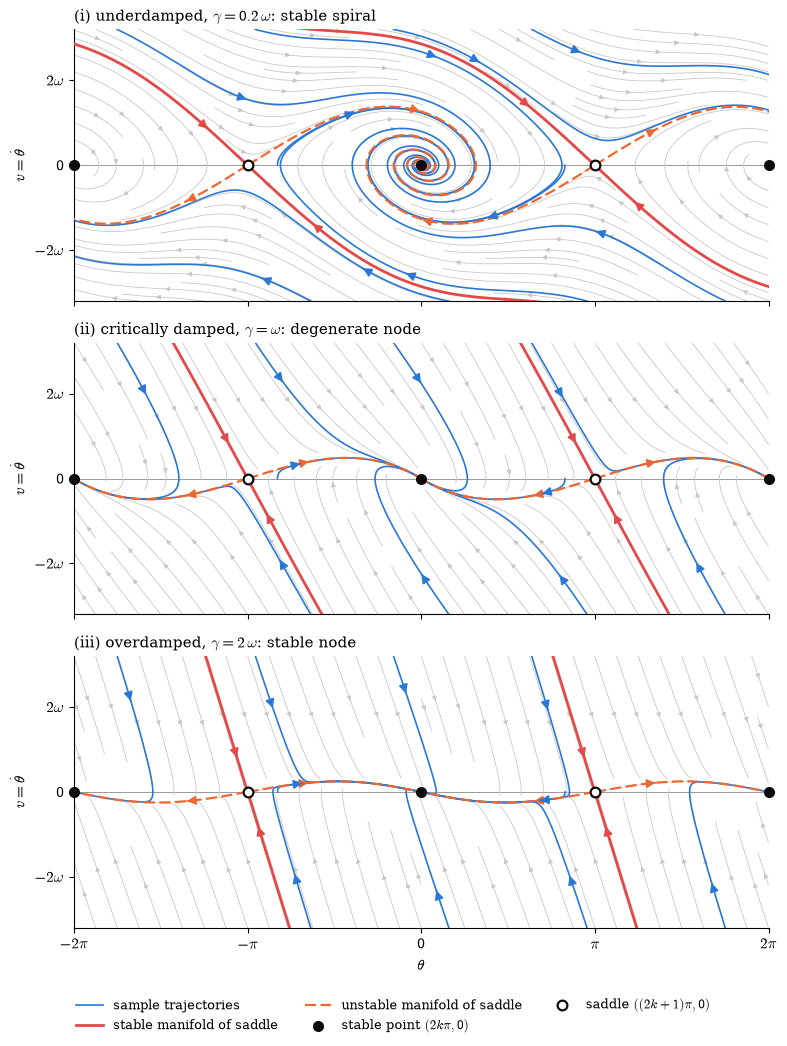

In [ ]:
def panel(ax, gamma, title):
    # background vector field
    th = np.linspace(-TH_MAX, TH_MAX, 200)
    v = np.linspace(-V_MAX, V_MAX, 120)
    TH, V = np.meshgrid(th, v)
    ax.streamplot(TH, V, V, -2 * gamma * V - omega**2 * np.sin(TH),
                  color=C_FIELD, linewidth=0.6, density=1.1, arrowsize=0.7, zorder=1)

    # saddle manifolds at theta = +-pi
    root = np.sqrt(gamma**2 + omega**2)
    lam_s, lam_u = -gamma - root, -gamma + root
    eps = 1e-6
    for ts in (-np.pi, np.pi):
        for sgn in (+1, -1):
            y = integrate(rhs_backward(gamma), [ts + sgn * eps, sgn * eps * lam_s])
            ax.plot(y[0], y[1], color=RED, lw=2.0, zorder=3)
            arrow_on(ax, y[0][::-1], y[1][::-1], RED, frac=0.75)   # reverse: forward time
            y = integrate(rhs(gamma), [ts + sgn * eps, sgn * eps * lam_u])
            ax.plot(y[0], y[1], color=ORANGE, lw=1.6, ls=(0, (5, 2)), zorder=3)
            arrow_on(ax, y[0], y[1], ORANGE, frac=0.35)

    # sample trajectories
    starts = [(-5.5, V_MAX), (-3.0, V_MAX), (-0.5, V_MAX), (2.0, V_MAX),
              (5.5, -V_MAX), (3.0, -V_MAX), (0.5, -V_MAX), (-2.0, -V_MAX),
              (2.6, 0.0), (-2.6, 0.0)]
    for y0 in starts:
        y = integrate(rhs(gamma), list(y0))
        ax.plot(y[0], y[1], color=BLUE, lw=1.2, zorder=2)
        arrow_on(ax, y[0], y[1], BLUE, frac=0.2)

    # equilibria
    ax.plot([-2 * np.pi, 0, 2 * np.pi], [0] * 3, "o", ms=7, color=C_INK, zorder=6,
            clip_on=False)
    ax.plot([-np.pi, np.pi], [0, 0], "o", ms=7, mfc="white", mec=C_INK, mew=1.6, zorder=6)

    ax.axhline(0, color=C_MUTED, lw=0.6, zorder=0)
    ax.set_xlim(-TH_MAX, TH_MAX)
    ax.set_ylim(-V_MAX, V_MAX)
    ax.set_xticks(np.arange(-2, 3) * np.pi)
    ax.set_xticklabels([r"$-2\pi$", r"$-\pi$", r"$0$", r"$\pi$", r"$2\pi$"])
    ax.set_yticks([-2, 0, 2])
    ax.set_yticklabels([r"$-2\omega$", r"$0$", r"$2\omega$"])
    ax.set_ylabel(r"$v=\dot\theta$")
    ax.set_title(title, fontsize=11, loc="left")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


cases = [
    (0.2, r"(i) underdamped, $\gamma = 0.2\,\omega$: stable spiral"),
    (1.0, r"(ii) critically damped, $\gamma = \omega$: degenerate node"),
    (2.0, r"(iii) overdamped, $\gamma = 2\,\omega$: stable node"),
]
fig, axes = plt.subplots(3, 1, figsize=(8, 10.5), sharex=True)
for ax, (g, title) in zip(axes, cases):
    panel(ax, g, title)
axes[-1].set_xlabel(r"$\theta$")

handles = [
    Line2D([], [], color=BLUE, lw=1.2, label="sample trajectories"),
    Line2D([], [], color=RED, lw=2.0, label="stable manifold of saddle"),
    Line2D([], [], color=ORANGE, lw=1.6, ls=(0, (5, 2)), label="unstable manifold of saddle"),
    Line2D([], [], ls="", marker="o", ms=7, color=C_INK, label=r"stable point $(2k\pi,0)$"),
    Line2D([], [], ls="", marker="o", ms=7, mfc="white", mec=C_INK, mew=1.6,
           label=r"saddle $((2k+1)\pi,0)$"),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9.5)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save(fig, "P1b_phase_portraits_damped")
plt.show()

## (c) Lyapunov stability — energy along a damped trajectory

$\dot E = -2\gamma v^2 \le 0$. At turning points ($v=0$, found with a `solve_ivp` event), $\dot E = 0$, but $E(t)$ only has an inflection there and keeps decreasing.
Start from rest at $\theta(0) = 2.5$, so $E(0) \approx 1.80\,\omega^2 < 2\omega^2$ and the pendulum stays in its well.
The dashed curve is the weak-damping estimate $E(0)e^{-2\gamma t}$.

E(0) = 1.8011 omega^2,  E is non-increasing: True
saved /home/stavros/Desktop/UOC MASTERS COURSES/Mathematical methods/5 Problem sets/MMP Set 2 Vogiatzis/Images/P1c_energy_decay.pdf


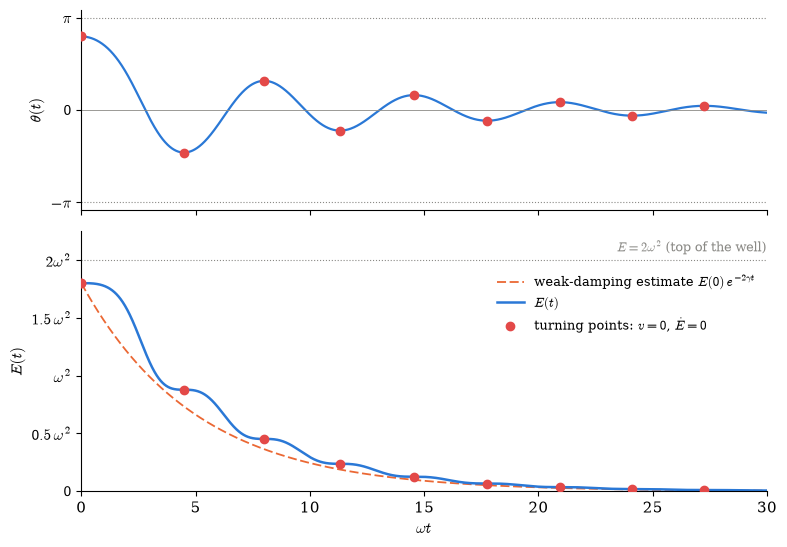

In [5]:
gamma = 0.1
theta0, v0 = 2.5, 0.0          # E(0) = 1 - cos(2.5) ~ 1.80 < 2
T = 30.0


def turning(t, y):
    return y[1]                # event: v = 0


sol = solve_ivp(rhs(gamma), (0, T), [theta0, v0], events=turning, dense_output=True,
                max_step=0.01, rtol=1e-10, atol=1e-12)
t = np.linspace(0, T, 4000)
th, v = sol.sol(t)
E = 0.5 * v**2 + omega**2 * (1 - np.cos(th))

t_turn = np.concatenate([[0.0], sol.t_events[0]])
th_turn = sol.sol(t_turn)[0]
E_turn = omega**2 * (1 - np.cos(th_turn))      # v = 0 there
E0 = E[0]
print(f"E(0) = {E0:.4f} omega^2,  E is non-increasing: {np.all(np.diff(E) <= 1e-12)}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True,
                               gridspec_kw=dict(height_ratios=[1, 1.3]))

# theta(t)
ax1.plot(t, th, color=BLUE, lw=1.6)
ax1.plot(t_turn, th_turn, "o", ms=6, color=RED, zorder=5)
for y in (np.pi, -np.pi):
    ax1.axhline(y, color=C_MUTED, lw=0.8, ls=":")
ax1.axhline(0, color=C_MUTED, lw=0.6)
ax1.set_ylim(-3.4, 3.4)
ax1.set_yticks([-np.pi, 0, np.pi])
ax1.set_yticklabels([r"$-\pi$", r"$0$", r"$\pi$"])
ax1.set_ylabel(r"$\theta(t)$")

# E(t)
ax2.axhline(2 * omega**2, color=C_MUTED, lw=0.8, ls=":")
ax2.text(T, 2 * omega**2 + 0.05, r"$E=2\omega^2$ (top of the well)", ha="right",
         va="bottom", fontsize=9, color=C_MUTED)
ax2.plot(t, E0 * np.exp(-2 * gamma * t), color=ORANGE, lw=1.3, ls=(0, (5, 2)),
         label=r"weak-damping estimate $E(0)\,e^{-2\gamma t}$")
ax2.plot(t, E, color=BLUE, lw=1.8, label=r"$E(t)$")
ax2.plot(t_turn, E_turn, "o", ms=6, color=RED, zorder=5,
         label=r"turning points: $v=0$, $\dot E=0$")
ax2.set_ylim(0, 2.25)
ax2.set_yticks([0, 0.5, 1, 1.5, 2])
ax2.set_yticklabels([r"$0$", r"$0.5\,\omega^2$", r"$\omega^2$", r"$1.5\,\omega^2$",
                     r"$2\omega^2$"])
ax2.set_ylabel(r"$E(t)$")
ax2.set_xlabel(r"$\omega t$")
ax2.set_xlim(0, T)
ax2.legend(loc="upper right", bbox_to_anchor=(1, 0.88), frameon=False, fontsize=9.5)

for ax in (ax1, ax2):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

fig.tight_layout()
save(fig, "P1c_energy_decay")
plt.show()